# Section 4: Does Rework Help?

Compare units labeled "Use As Is" with units labeled "Rework Completed."

We will:
1. Check the meaning of the labels and compare group characteristics.
2. Compare field outcomes, costs, and days-to-failure.
3. Assess recorded plant spending against measurable differences.

Every supplied unit experienced a field failure. Our results describe
these failed units and cannot establish how many failures rework
prevented across all production.

## 4.1 Disposition definitions and group comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from scipy.stats import chi2_contingency

df = pd.read_excel("DataSets/Competition_Dataset_Final.xlsx")

groups = ["Use As Is", "Rework Completed"]

assert df["Serial Number"].is_unique
assert df.notna().all().all()
assert set(df["Disposition Code"]) == set(groups)

group_counts = (
    df["Disposition Code"]
    .value_counts()
    .reindex(groups)
)

group_summary = pd.DataFrame({
    "Units": group_counts,
    "Percent": 100 * group_counts / len(df)
})

display(group_summary.round(2))

,Units,Percent
Disposition Code,,
Use As Is,1511,50.37
Rework Completed,1489,49.63


In [2]:
disposition_audit = (
    df.groupby("Disposition Code")
    .agg(
        Units=("Serial Number", "size"),
        Positive_labor_rows=(
            "Labor Hours Rework",
            lambda x: int((x > 0).sum())
        ),
        Positive_material_rows=(
            "Material Cost Rework",
            lambda x: int((x > 0).sum())
        ),
        Labor_hours=("Labor Hours Rework", "sum"),
        Material_cost=("Material Cost Rework", "sum")
    )
    .reindex(groups)
)

display(disposition_audit.round(2))

# Check whether plant and field category labels vary independently.
display(pd.crosstab(
    df["Defect Category"],
    df["Failure Category"]
))

,Units,Positive_labor_rows,Positive_material_rows,Labor_hours,Material_cost
Disposition Code,,,,,
Use As Is,1511,1511,1511,4853.7,394267
Rework Completed,1489,1489,1489,4804.1,400117


Failure Category,Controls,Leak,Wiring
Defect Category,,,
Brazing,0,788,0
Controls,283,0,0
Wiring,0,0,1929


### Disposition and category audit

Both disposition groups contain positive recorded labor and material
costs for every unit.

Therefore, "Use As Is" cannot automatically be interpreted as receiving
no repair activity or incurring no plant cost. We need confirmation of
what activities occurred before the disposition decision and what
the recorded costs include.

The plant and field category labels also correspond exactly:
- Brazing corresponds to Leak.
- Controls corresponds to Controls.
- Wiring corresponds to Wiring.

Consequently, field-category comparisons within each defect category
contain no variation in this sample. Later comparisons will also examine
detailed failure descriptions, cost, and days-to-failure.

We will treat disposition comparisons as observational evidence while
these definitions remain unresolved.

In [3]:
features = [
    "Facility",
    "Coil Supplier",
    "Shift",
    "Product Family",
    "Controls Revision",
    "Defect Category"
]

profile_rows = []
test_rows = []

for feature in features:
    counts = pd.crosstab(
        df[feature], df["Disposition Code"]
    ).reindex(columns=groups)

    percentages = 100 * counts.div(
        counts.sum(axis=0), axis=1
    )

    gaps = (
        percentages["Rework Completed"]
        - percentages["Use As Is"]
    )

    for level in counts.index:
        profile_rows.append({
            "Characteristic": feature,
            "Level": level,
            "Use As Is (%)": percentages.loc[level, "Use As Is"],
            "Rework Completed (%)": percentages.loc[
                level, "Rework Completed"
            ],
            "Difference (pp)": gaps.loc[level]
        })

    chi2, p_value, dof, expected = chi2_contingency(
        counts, correction=False
    )

    assert expected.min() >= 5, (
        f"Small expected counts for {feature}; review test method."
    )

    test_rows.append({
        "Characteristic": feature,
        "Raw p": p_value,
        "Largest gap (pp)": gaps.abs().max()
    })

balance = pd.DataFrame(profile_rows)
balance_tests = pd.DataFrame(test_rows)

display(balance.round(2))

,Characteristic,Level,Use As Is (%),Rework Completed (%),Difference (pp)
0,Facility,Facility 1,24.22,25.65,1.43
1,Facility,Facility 2,25.94,26.33,0.38
2,Facility,Facility 3,26.80,23.30,-3.50
3,Facility,Facility 4,23.03,24.71,1.68
4,Coil Supplier,Supplier A,33.88,35.39,1.51
5,Coil Supplier,Supplier B,30.64,28.95,-1.70
6,Coil Supplier,Supplier C,35.47,35.66,0.19
7,Shift,Day,58.57,61.52,2.95
8,Shift,Night,41.43,38.48,-2.95
9,Product Family,DC100,23.63,25.65,2.03


In [4]:
p_values = balance_tests["Raw p"].to_numpy()
order = np.argsort(p_values)

adjusted = np.empty(len(p_values))

adjusted[order] = np.minimum(
    1.0,
    np.maximum.accumulate(
        p_values[order]
        * (len(p_values) - np.arange(len(p_values)))
    )
)

balance_tests["Holm p"] = adjusted

display(
    balance_tests[
        ["Characteristic", "Largest gap (pp)", "Raw p", "Holm p"]
    ].round(4)
)

,Characteristic,Largest gap (pp),Raw p,Holm p
0,Facility,3.4992,0.1568,0.6273
1,Coil Supplier,1.6964,0.5422,1.0000
2,Shift,2.9473,0.0994,0.4970
3,Product Family,2.0281,0.5735,1.0000
4,Controls Revision,4.2129,0.0370,0.2221
5,Defect Category,2.4571,0.2120,0.6361


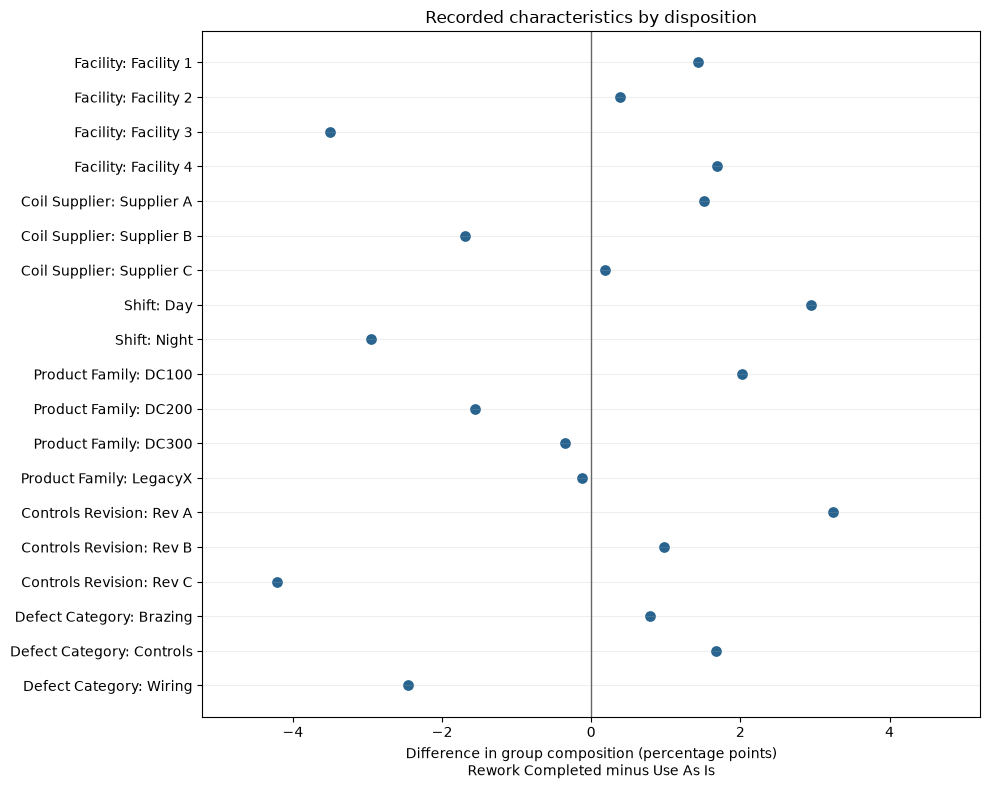

In [5]:
figures = Path("Figures") / "Section4"
figures.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 8))

positions = np.arange(len(balance))

ax.scatter(
    balance["Difference (pp)"],
    positions,
    color="#28648F",
    s=45
)

ax.axvline(0, color="#666666", linewidth=1)

ax.set_yticks(positions)
ax.set_yticklabels(
    balance["Characteristic"]
    + ": "
    + balance["Level"].astype(str)
)

ax.invert_yaxis()

limit = balance["Difference (pp)"].abs().max() + 1
ax.set_xlim(-limit, limit)

ax.set_xlabel(
    "Difference in group composition (percentage points)\n"
    "Rework Completed minus Use As Is"
)

ax.set_title("Recorded characteristics by disposition")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    figures / "disposition_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Initial group-comparison findings

The two disposition groups have similar sizes: 1,511 Use As Is units
and 1,489 Rework Completed units.

Across the recorded characteristics checked, the largest category-share
difference is for Rev C:
- Use As Is: 37.59%.
- Rework Completed: 33.38%.
- Difference: 4.21 percentage points.

Controls revision has a raw p-value of approximately 0.037.
After Holm adjustment across six tests, its p-value is approximately
0.222. No adjusted p-value is below 0.05.

These checks show modest differences in the recorded group profiles.
They do not establish random assignment, equivalence, or balance on
unrecorded characteristics such as defect severity.

The graph describes group composition. It does not measure the benefit
of rework.

### Implication for the outcome analysis

Proceed with comparisons of cost, days-to-failure, and detailed failure
descriptions, including comparisons within defect categories.

Report uncertainty and retain the observed group differences when
interpreting results. Treat conclusions as associations among the
supplied failed units unless assignment rules and treatment timing
can be verified.

## 4.2 Recorded outcome comparisons

Compare mean warranty expense and mean days-to-failure between
Rework Completed and Use As Is, overall and within each defect category.

Define each difference as:

Rework Completed minus Use As Is

- A negative warranty-cost difference indicates lower recorded expense.
- A positive days-to-failure difference indicates a longer observed
  time before failure.

These initial comparisons are unadjusted. Later checks will examine
revision and product-family differences.

All results describe the supplied failed units.

In [8]:
## 4.2 Recorded outcome comparisons

from scipy.stats import bootstrap

def mean_difference(a, b, axis=-1):
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)


subsets = {"Overall": df}

for name, subset in df.groupby("Defect Category"):
    subsets[name] = subset

rows = []

for label, subset in subsets.items():
    for outcome in ["Warranty Cost", "Days To Failure"]:
        rework = subset.loc[
            subset["Disposition Code"].eq("Rework Completed"),
            outcome
        ].to_numpy()

        use_as_is = subset.loc[
            subset["Disposition Code"].eq("Use As Is"),
            outcome
        ].to_numpy()

        result = bootstrap(
            (rework, use_as_is),
            mean_difference,
            vectorized=True,
            paired=False,
            n_resamples=10_000,
            batch=200,
            confidence_level=0.95,
            method="percentile",
            rng=np.random.default_rng(42)
        )

        rows.append({
            "Group": label,
            "Outcome": outcome,
            "Use As Is n": len(use_as_is),
            "Rework n": len(rework),
            "Use As Is mean": use_as_is.mean(),
            "Rework mean": rework.mean(),
            "Difference": mean_difference(rework, use_as_is),
            "CI low": result.confidence_interval.low,
            "CI high": result.confidence_interval.high
        })

outcome_comparison = pd.DataFrame(rows)

display(outcome_comparison.round(2))

,Group,Outcome,Use As Is n,Rework n,Use As Is mean,Rework mean,Difference,CI low,CI high
0,Overall,Warranty Cost,1511,1489,2465.51,2638.07,172.56,-51.38,397.22
1,Overall,Days To Failure,1511,1489,127.34,122.77,-4.58,-9.33,0.18
2,Brazing,Warranty Cost,391,397,7197.24,7481.87,284.63,21.57,555.78
3,Brazing,Days To Failure,391,397,130.94,122.47,-8.47,-17.71,0.81
4,Controls,Warranty Cost,130,153,2689.49,2846.24,156.75,-95.51,405.92
5,Controls,Days To Failure,130,153,123.99,132.10,8.11,-6.86,22.75
6,Wiring,Warranty Cost,990,939,567.31,556.24,-11.07,-35.73,13.87
7,Wiring,Days To Failure,990,939,126.36,121.37,-4.99,-10.91,0.92


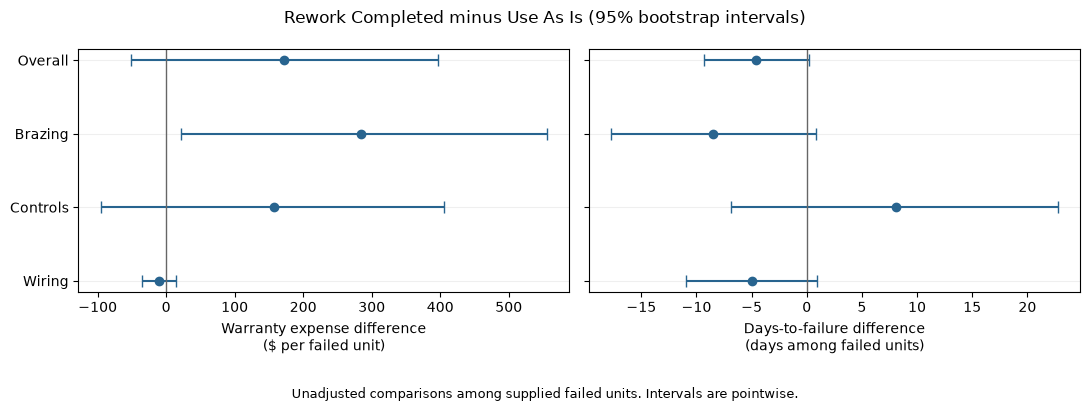

In [9]:
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), sharey=True
)

outcomes = ["Warranty Cost", "Days To Failure"]

axis_labels = [
    "Warranty expense difference\n($ per failed unit)",
    "Days-to-failure difference\n(days among failed units)"
]

for ax, outcome, axis_label in zip(
    axes, outcomes, axis_labels
):
    values = outcome_comparison.loc[
        outcome_comparison["Outcome"].eq(outcome)
    ]

    positions = np.arange(len(values))

    errors = np.vstack([
        values["Difference"] - values["CI low"],
        values["CI high"] - values["Difference"]
    ])

    ax.errorbar(
        values["Difference"],
        positions,
        xerr=errors,
        fmt="o",
        color="#28648F",
        capsize=4
    )

    ax.axvline(0, color="#666666", linewidth=1)
    ax.set_yticks(positions)
    ax.set_yticklabels(values["Group"])
    ax.set_xlabel(axis_label)
    ax.grid(axis="y", alpha=0.2)

axes[0].invert_yaxis()

fig.suptitle(
    "Rework Completed minus Use As Is "
    "(95% bootstrap intervals)"
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

fig.text(
    0.5, 0.01,
    "Unadjusted comparisons among supplied failed units. "
    "Intervals are pointwise.",
    ha="center",
    fontsize=9
)

figures = Path("Figures") / "Section4"
figures.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures / "outcome_differences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Initial outcome findings

Overall, Rework Completed cases have:
- $172.56 higher mean warranty expense per unit.
- 4.58 fewer mean days-to-failure.

The overall 95% bootstrap intervals are:
- Warranty difference: −$51.38 to +$397.22.
- Days-to-failure difference: −9.33 to +0.18 days.

Both overall intervals include zero. This comparison does not detect
a clear overall difference and does not establish that rework has
no effect.

Within Brazing cases, Rework Completed has $284.63 higher mean warranty
expense, with an interval of approximately +$21.57 to +$555.78.
This higher-cost signal deserves investigation.

These are exploratory, pointwise 95% intervals: each covers one
comparison, rather than all eight comparisons together.

The comparisons assume independent units and remain unadjusted.
They do not establish that rework caused the observed differences.

Next, examine detailed failure descriptions and whether revision
or product-family mix, particularly LegacyX, explains the patterns.

### Accounting for differences in case mix

Compare outcomes while giving both disposition groups the same
distribution of controls revision, defect category, and product family.

Calculate differences within each combination, then combine them
using that combination's share of the full dataset.

This follows up the revision difference identified in Section 4.1.
It also accounts for defect and product-family differences that
could affect recorded costs.

These are descriptive comparisons among failed units. Unclear
disposition definitions and other unrecorded differences remain.

In [10]:
from scipy.stats import bootstrap

def standardized_difference(data, outcome, factors):
    if factors:
        combinations = list(
            data.groupby(factors, observed=True)
        )
    else:
        combinations = [("Overall", data)]

    samples = []
    weights = []
    sizes = []

    for name, part in combinations:
        rework = part.loc[
            part["Disposition Code"].eq("Rework Completed"),
            outcome
        ].to_numpy()

        use_as_is = part.loc[
            part["Disposition Code"].eq("Use As Is"),
            outcome
        ].to_numpy()

        if len(rework) == 0 or len(use_as_is) == 0:
            raise ValueError(
                f"Both dispositions are needed in combination {name}."
            )

        samples.extend([rework, use_as_is])
        weights.append(len(part) / len(data))
        sizes.extend([len(rework), len(use_as_is)])

    def statistic(*arrays, axis=-1):
        return sum(
            weight * (
                np.mean(arrays[2 * i], axis=axis)
                - np.mean(arrays[2 * i + 1], axis=axis)
            )
            for i, weight in enumerate(weights)
        )

    result = bootstrap(
        tuple(samples),
        statistic,
        vectorized=True,
        paired=False,
        n_resamples=10_000,
        batch=200,
        confidence_level=0.95,
        method="percentile",
        rng=np.random.default_rng(42)
    )

    return {
        "Difference": statistic(*samples),
        "CI low": result.confidence_interval.low,
        "CI high": result.confidence_interval.high,
        "Combinations": len(combinations),
        "Smallest subgroup n": min(sizes)
    }


settings = {
    "Unadjusted": [],
    "Same revision mix": ["Controls Revision"],
    "Same revision, defect and family mix": [
        "Controls Revision",
        "Defect Category",
        "Product Family"
    ]
}

rows = []

for label, factors in settings.items():
    for outcome in ["Warranty Cost", "Days To Failure"]:
        rows.append({
            "Comparison": label,
            "Outcome": outcome,
            **standardized_difference(df, outcome, factors)
        })

standardized_results = pd.DataFrame(rows)

display(standardized_results.round(2))

,Comparison,Outcome,Difference,CI low,CI high,Combinations,Smallest subgroup n
0,Unadjusted,Warranty Cost,172.56,-51.38,397.22,1,1489
1,Unadjusted,Days To Failure,-4.58,-9.33,0.18,1,1489
2,Same revision mix,Warranty Cost,146.67,-69.59,372.21,3,426
3,Same revision mix,Days To Failure,-4.72,-9.47,0.06,3,426
4,"Same revision, defect and family mix",Warranty Cost,63.40,5.09,121.38,28,16
5,"Same revision, defect and family mix",Days To Failure,-4.89,-9.58,-0.12,28,16


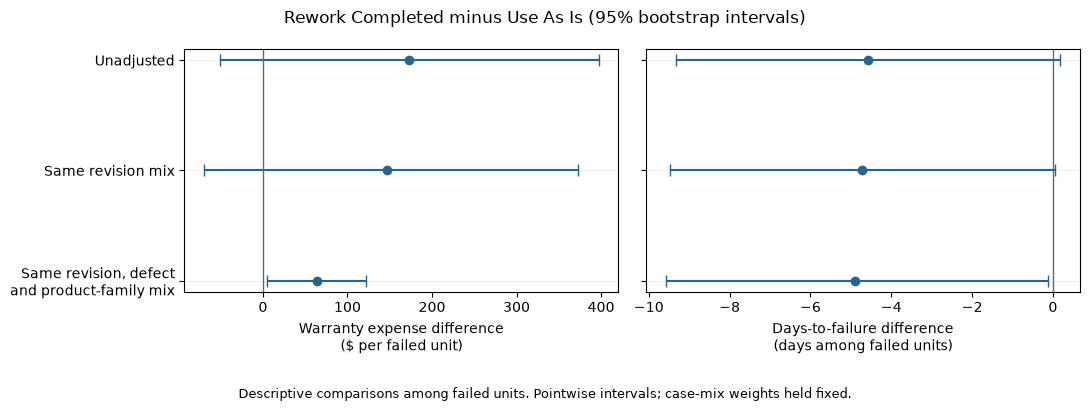

In [11]:
from pathlib import Path

figures = Path("Figures") / "Section4"
figures.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), sharey=True
)

labels = [
    "Unadjusted",
    "Same revision mix",
    "Same revision, defect\nand product-family mix"
]

for ax, outcome, xlabel in zip(
    axes,
    ["Warranty Cost", "Days To Failure"],
    [
        "Warranty expense difference\n($ per failed unit)",
        "Days-to-failure difference\n(days among failed units)"
    ]
):
    values = standardized_results.loc[
        standardized_results["Outcome"].eq(outcome)
    ]

    positions = np.arange(len(values))

    errors = np.vstack([
        values["Difference"] - values["CI low"],
        values["CI high"] - values["Difference"]
    ])

    ax.errorbar(
        values["Difference"],
        positions,
        xerr=errors,
        fmt="o",
        capsize=4,
        color="#28648F"
    )

    ax.axvline(0, color="#666666", linewidth=1)
    ax.set_yticks(positions)
    ax.set_yticklabels(labels)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", alpha=0.2)

axes[0].invert_yaxis()

fig.suptitle(
    "Rework Completed minus Use As Is "
    "(95% bootstrap intervals)"
)

fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.text(
    0.5, 0.01,
    "Descriptive comparisons among failed units. "
    "Pointwise intervals; case-mix weights held fixed.",
    ha="center",
    fontsize=9
)

fig.savefig(
    figures / "standardized_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Results after accounting for case mix

Giving both groups the same revision mix changes the estimated
warranty difference from +$172.56 to +$146.67 per failed unit.

After also accounting for defect category and product family:
- Warranty expense is $63.40 higher in Rework Completed records.
- Recorded days-to-failure is 4.89 days lower.

The corresponding pointwise 95% bootstrap intervals are:
- Warranty expense: +$5.09 to +$121.38.
- Days-to-failure: −9.58 to −0.12 days.

Both dispositions are represented in all 28 combinations.
The smallest disposition subgroup contains 16 units.

These results do not show a favorable cost or days-to-failure pattern
for Rework Completed among the supplied failed units. They do not
establish that rework caused worse outcomes.

The intervals are exploratory and pointwise. They assume independent
units and hold the observed case-mix weights fixed. Other differences,
including unrecorded defect severity, may remain.

Because every supplied unit failed, this analysis cannot estimate
failures prevented by rework.

### Detailed field failure descriptions

Compare the share of each failure description between dispositions,
overall and within each defect category.

Using detailed descriptions provides information beyond the fixed
mapping between plant defect category and field failure category.

Each difference is:

Rework Completed percentage minus Use As Is percentage

These percentages describe the mix of observed failures, not the
probability that a manufactured unit will fail.

In [12]:
scopes = {"Overall": df}

for name, part in df.groupby("Defect Category"):
    scopes[name] = part

rows = []

for label, part in scopes.items():
    rework = part.loc[
        part["Disposition Code"].eq("Rework Completed"),
        "Failure Description"
    ]

    use_as_is = part.loc[
        part["Disposition Code"].eq("Use As Is"),
        "Failure Description"
    ]

    for description in sorted(part["Failure Description"].unique()):
        a = rework.eq(description).astype(int).to_numpy()
        b = use_as_is.eq(description).astype(int).to_numpy()

        result = bootstrap(
            (a, b),
            mean_difference,
            vectorized=True,
            paired=False,
            n_resamples=10_000,
            batch=200,
            confidence_level=0.95,
            method="percentile",
            rng=np.random.default_rng(42)
        )

        rows.append({
            "Scope": label,
            "Failure description": description,
            "Use As Is n": len(b),
            "Rework n": len(a),
            "Use As Is (%)": 100 * b.mean(),
            "Rework (%)": 100 * a.mean(),
            "Difference (pp)": 100 * mean_difference(a, b),
            "CI low (pp)": 100 * result.confidence_interval.low,
            "CI high (pp)": 100 * result.confidence_interval.high
        })

failure_comparison = pd.DataFrame(rows)

display(failure_comparison.round(2))

,Scope,Failure description,Use As Is n,Rework n,Use As Is (%),Rework (%),Difference (pp),CI low (pp),CI high (pp)
0,Overall,Communication Fault,1511,1489,4.30,5.24,0.94,-0.54,2.47
1,Overall,Condenser Fan Backwards,1511,1489,5.76,6.58,0.82,-0.91,2.55
2,Overall,Loose Power Wiring,1511,1489,59.76,56.48,-3.28,-6.87,0.31
3,Overall,Refrigerant Leak,1511,1489,7.81,8.87,1.06,-0.88,3.05
4,Overall,Sensor Fault,1511,1489,4.30,5.04,0.74,-0.80,2.27
5,Overall,Service Valve Leak,1511,1489,9.33,8.66,-0.67,-2.73,1.39
6,Overall,Suction Leak,1511,1489,8.74,9.13,0.40,-1.60,2.47
7,Brazing,Refrigerant Leak,391,397,30.18,33.25,3.07,-3.52,9.46
8,Brazing,Service Valve Leak,391,397,36.06,32.49,-3.57,-10.19,3.02
9,Brazing,Suction Leak,391,397,33.76,34.26,0.50,-6.11,7.09


### Detailed failure-pattern findings

All detailed failure-description intervals include zero, both overall
and within defect categories. This analysis detects no clear differences
in the description shares between dispositions.

For example, within Wiring cases:
- Backward fans represent 10.44% of Rework Completed cases.
- They represent 8.79% of Use As Is cases.
- The difference is +1.65 percentage points, with a 95% interval
  of approximately −0.96 to +4.25 percentage points.

These results do not establish that the distributions are identical
or that rework prevents no failures.

### Section 4.2 conclusion

The supplied failure records do not show an observed cost or
days-to-failure advantage for Rework Completed after accounting for
revision, defect category, and product-family mix.

Detailed failure descriptions also show no clear differences between
dispositions in these comparisons.

These findings describe associations among failed units. Assessing
whether rework prevents failures requires records for units that
did not fail and clearer information about the disposition decision
and work performed.3

## 4.3 Recorded plant spending versus measurable benefit

Summarize material expense and labor hours by disposition.

Compare averages per unit because the disposition groups contain
different numbers of units.

Convert labor hours into dollars only when an agreed hourly cost
is available. Keep EOLT hours separate until their overlap with
plant rework hours is understood.

These figures describe recorded activity. They do not establish
additional spending caused by the disposition decision.

In [13]:
groups = ["Use As Is", "Rework Completed"]

plant_summary = (
    df.groupby("Disposition Code")
    .agg(
        Units=("Serial Number", "size"),
        Material_total=("Material Cost Rework", "sum"),
        Labor_hours_total=("Labor Hours Rework", "sum"),
        EOLT_hours_total=("EOLT Rework Hours", "sum"),
        Material_per_unit=("Material Cost Rework", "mean"),
        Labor_hours_per_unit=("Labor Hours Rework", "mean")
    )
    .reindex(groups)
)

display(plant_summary.round(2))

,Units,Material_total,Labor_hours_total,EOLT_hours_total,Material_per_unit,Labor_hours_per_unit
Disposition Code,,,,,,
Use As Is,1511,394267,4853.7,3173.2,260.93,3.21
Rework Completed,1489,400117,4804.1,3100.9,268.72,3.23


In [14]:
rows = []

for column in ["Material Cost Rework", "Labor Hours Rework"]:
    rework = df.loc[
        df["Disposition Code"].eq("Rework Completed"),
        column
    ].to_numpy()

    use_as_is = df.loc[
        df["Disposition Code"].eq("Use As Is"),
        column
    ].to_numpy()

    result = bootstrap(
        (rework, use_as_is),
        mean_difference,
        vectorized=True,
        paired=False,
        n_resamples=10_000,
        batch=200,
        confidence_level=0.95,
        method="percentile",
        rng=np.random.default_rng(42)
    )

    rows.append({
        "Measure": column,
        "Difference per unit": mean_difference(rework, use_as_is),
        "CI low": result.confidence_interval.low,
        "CI high": result.confidence_interval.high
    })

plant_differences = pd.DataFrame(rows)

display(plant_differences.round(3))

,Measure,Difference per unit,CI low,CI high
0,Material Cost Rework,7.784,-2.177,17.793
1,Labor Hours Rework,0.014,-0.098,0.131


In [15]:
LABOR_RATE = None

if LABOR_RATE is not None:
    assert LABOR_RATE >= 0

    plant_summary["Material plus labor total"] = (
        plant_summary["Material_total"]
        + LABOR_RATE * plant_summary["Labor_hours_total"]
    )

    plant_summary["Material plus labor per unit"] = (
        plant_summary["Material_per_unit"]
        + LABOR_RATE * plant_summary["Labor_hours_per_unit"]
    )

    display(plant_summary.round(2))
else:
    print(
        "Labor dollars remain uncalculated. "
        "Set LABOR_RATE when an agreed hourly cost is available."
    )

Labor dollars remain uncalculated. Set LABOR_RATE when an agreed hourly cost is available.


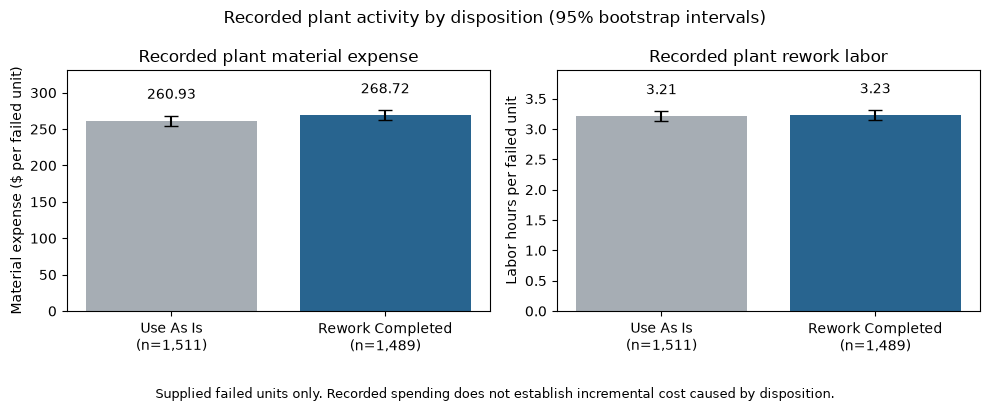

In [16]:
rows = []

for column in ["Material Cost Rework", "Labor Hours Rework"]:
    for disposition in groups:
        values = df.loc[
            df["Disposition Code"].eq(disposition),
            column
        ].to_numpy()

        result = bootstrap(
            (values,),
            np.mean,
            vectorized=True,
            n_resamples=10_000,
            batch=200,
            confidence_level=0.95,
            method="percentile",
            rng=np.random.default_rng(42)
        )

        rows.append({
            "Measure": column,
            "Disposition": disposition,
            "Mean": values.mean(),
            "CI low": result.confidence_interval.low,
            "CI high": result.confidence_interval.high
        })

plant_means = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, column, title, ylabel in zip(
    axes,
    ["Material Cost Rework", "Labor Hours Rework"],
    ["Recorded plant material expense", "Recorded plant rework labor"],
    [
        "Material expense ($ per failed unit)",
        "Labor hours per failed unit"
    ]
):
    values = (
        plant_means.loc[plant_means["Measure"].eq(column)]
        .set_index("Disposition")
        .loc[groups]
    )

    errors = np.vstack([
        values["Mean"] - values["CI low"],
        values["CI high"] - values["Mean"]
    ])

    bars = ax.bar(
        np.arange(2),
        values["Mean"],
        yerr=errors,
        capsize=5,
        color=["#A6ADB4", "#28648F"]
    )

    ax.set_xticks(np.arange(2))
    ax.set_xticklabels([
        f"{group}\n(n={int(plant_summary.loc[group, 'Units']):,})"
        for group in groups
    ])

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, values["CI high"].max() * 1.2)
    ax.bar_label(bars, fmt="%.2f", padding=10)

fig.suptitle(
    "Recorded plant activity by disposition "
    "(95% bootstrap intervals)"
)

fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.text(
    0.5, 0.01,
    "Supplied failed units only. Recorded spending does not "
    "establish incremental cost caused by disposition.",
    ha="center",
    fontsize=9
)

figures = Path("Figures") / "Section4"
figures.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures / "plant_spending.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Recorded plant-cost findings

Rework Completed records contain:
- $400,117 in material expense.
- 4,804.1 plant rework labor hours.

Use As Is records contain:
- $394,267 in material expense.
- 4,853.7 plant rework labor hours.

At an agreed labor rate of R dollars per hour, recorded material
plus plant labor expense would be:

- Rework Completed: $400,117 + (4,804.1 × R).
- Use As Is: $394,267 + (4,853.7 × R).

These totals cover different numbers of units, so compare per-unit
averages when assessing differences.

Rework Completed has:
- $7.78 higher mean material expense per unit.
- 0.014 additional mean labor hours per unit.

The pointwise 95% bootstrap intervals for these differences are:
- Material expense: approximately −$2.18 to +$17.79.
- Labor hours: approximately −0.098 to +0.131 hours.

Both intervals include zero. These unadjusted comparisons detect
no clear differences in average recorded material expense or labor hours.

Both dispositions contain recorded plant activity. We cannot treat
all spending on Rework Completed records as additional or avoidable
spending caused by that disposition.

EOLT hours remain separate. Section 3's fan-related plant costs are
subsets of these records, so the section totals must not be added together.

## Section 4 conclusion

Among the supplied failed units, Rework Completed records show no
observed warranty-cost or days-to-failure advantage after accounting
for revision, defect category, and product-family mix.

Recorded plant material expense and labor hours are similar between
dispositions, with uncertainty around the estimated differences.

These findings do not establish that rework is ineffective or harmful.
Every supplied unit failed, and disposition does not provide a complete
history of the work performed.

A defensible production-wide return on rework cannot be calculated
from these records alone. It requires clearer activity and cost
definitions, plus follow-up records for all units, including those
that did not fail.

The recommended next step is to connect actual work performed,
its timing and costs, and subsequent outcomes across all production
before changing rework policy.

In [17]:
scopes = {"Overall": df}

for name, part in df.groupby("Defect Category"):
    scopes[name] = part

rows = []

for label, part in scopes.items():
    averages = part.groupby("Disposition Code")[
        ["Material Cost Rework", "Labor Hours Rework"]
    ].mean()

    differences = (
        averages.loc["Rework Completed"]
        - averages.loc["Use As Is"]
    )

    material_gap = differences["Material Cost Rework"]
    hours_gap = differences["Labor Hours Rework"]

    crossover = (
        -material_gap / hours_gap
        if abs(hours_gap) > 1e-12
        else np.nan
    )

    rows.append({
        "Comparison": label,
        "Material difference ($/unit)": material_gap,
        "Labor difference (hours/unit)": hours_gap,
        "Point crossover ($/hour)": (
            f"{crossover:.2f}"
            if np.isfinite(crossover) and crossover >= 0
            else "No positive crossover"
        )
    })

crossover_table = pd.DataFrame(rows)

display(crossover_table.round(3))

,Comparison,Material difference ($/unit),Labor difference (hours/unit),Point crossover ($/hour)
0,Overall,7.784,0.014,No positive crossover
1,Brazing,-8.577,0.098,87.36
2,Controls,28.242,0.063,No positive crossover
3,Wiring,11.714,-0.023,499.85


### Labor-rate sensitivity

The assumed labor rate can change the recorded plant-cost ranking.

Within Brazing cases, Rework Completed records have lower average
material expense but more labor hours. Their estimated plant-cost
ranking reverses at approximately $87.36 per hour.

This is a crossover based on observed averages, not a confirmed
economic break-even for rework. Bootstrap uncertainty includes zero
across the illustrated $0–$200/hour range.

The analysis assumes a common labor rate across groups. Any benchmark
rate must be labeled with its source, geography, date, and limitations.

The overall recorded per-unit cost estimates have no positive-rate
crossover. Production-wide cost-effectiveness remains unresolved
because failures prevented and incremental rework spending are unknown.

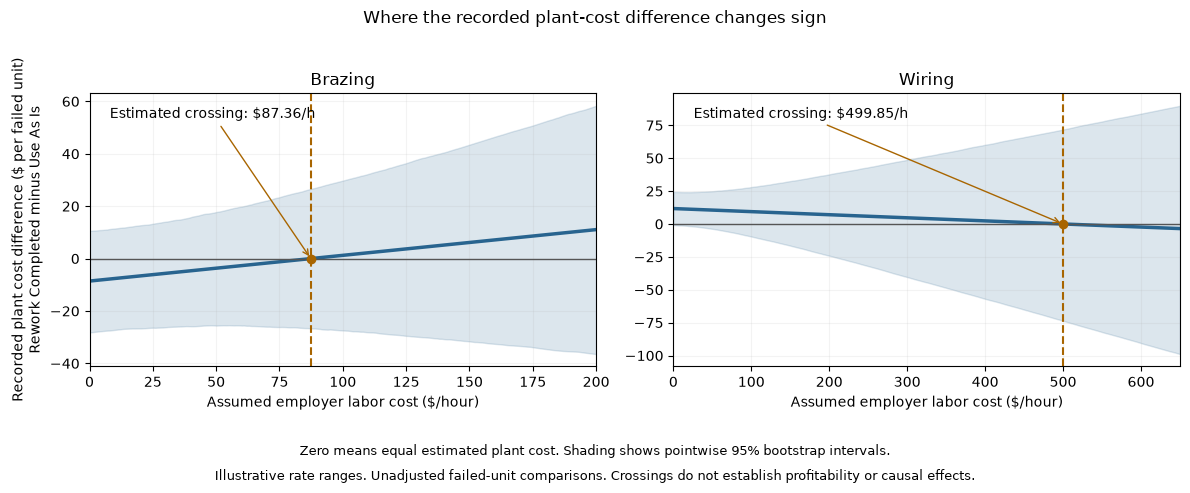

In [18]:
columns = ["Material Cost Rework", "Labor Hours Rework"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, defect, maximum_rate in zip(
    axes,
    ["Brazing", "Wiring"],
    [200, 650]
):
    part = df.loc[df["Defect Category"].eq(defect)]

    # Keep each unit's material cost and hours together.
    rework = part.loc[
        part["Disposition Code"].eq("Rework Completed"),
        columns
    ].to_numpy().T

    use_as_is = part.loc[
        part["Disposition Code"].eq("Use As Is"),
        columns
    ].to_numpy().T

    material_gap, hours_gap = mean_difference(
        rework, use_as_is
    )

    crossover = -material_gap / hours_gap
    rates = np.linspace(0, maximum_rate, 201)

    # Plant-cost difference at each assumed hourly rate.
    cost_gap = material_gap + hours_gap * rates

    # Resample unit records to estimate uncertainty.
    result = bootstrap(
        (rework, use_as_is),
        mean_difference,
        axis=-1,
        vectorized=True,
        paired=False,
        n_resamples=10_000,
        batch=200,
        confidence_level=0.95,
        method="percentile",
        rng=np.random.default_rng(42)
    )

    draws = result.bootstrap_distribution

    bootstrap_gaps = (
        draws[0, :, None]
        + draws[1, :, None] * rates[None, :]
    )

    low, high = np.quantile(
        bootstrap_gaps, [0.025, 0.975], axis=0
    )

    ax.fill_between(
        rates, low, high,
        color="#28648F", alpha=0.16
    )

    ax.plot(
        rates, cost_gap,
        color="#28648F", linewidth=2.5
    )

    # Zero means equal estimated plant cost.
    ax.axhline(0, color="#555555", linewidth=1)

    ax.axvline(
        crossover,
        color="#A86500",
        linestyle="--"
    )

    ax.scatter(
        [crossover], [0],
        color="#A86500", zorder=4
    )

    ax.annotate(
        f"Estimated crossing: ${crossover:.2f}/h",
        xy=(crossover, 0),
        xytext=(0.04, 0.91),
        textcoords="axes fraction",
        arrowprops={
            "arrowstyle": "->",
            "color": "#A86500"
        }
    )

    ax.set_title(defect)
    ax.set_xlim(0, maximum_rate)
    ax.set_xlabel("Assumed employer labor cost ($/hour)")
    ax.grid(alpha=0.15)

axes[0].set_ylabel(
    "Recorded plant cost difference ($ per failed unit)\n"
    "Rework Completed minus Use As Is"
)

fig.suptitle(
    "Where the recorded plant-cost difference changes sign"
)

fig.tight_layout(rect=[0, 0.15, 1, 0.95])

fig.text(
    0.5, 0.09,
    "Zero means equal estimated plant cost. "
    "Shading shows pointwise 95% bootstrap intervals.",
    ha="center", fontsize=9
)

fig.text(
    0.5, 0.04,
    "Illustrative rate ranges. Unadjusted failed-unit comparisons. "
    "Crossings do not establish profitability or causal effects.",
    ha="center", fontsize=9
)

figures = Path("Figures") / "Section4"
figures.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures / "brazing_wiring_crossovers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
from scipy.stats import t

model_data = df.assign(
    Defect_family=(
        df["Defect Category"] + " / " + df["Product Family"]
    )
)

features = [
    "Defect_family",
    "Controls Revision",
    "Facility",
    "Coil Supplier",
    "Shift"
]

design = pd.get_dummies(
    model_data[features],
    drop_first=True,
    dtype=float
)

design.insert(
    0, "Rework",
    df["Disposition Code"].eq("Rework Completed").astype(float)
)
design.insert(0, "Intercept", 1.0)

X = design.to_numpy()
n, parameters = X.shape

assert np.linalg.matrix_rank(X) == parameters

inverse = np.linalg.pinv(X)
leverage = np.sum(X * inverse.T, axis=1)
assert np.all(leverage < 1)

critical_value = t.ppf(0.975, n - parameters)

rows = []

for outcome in ["Warranty Cost", "Days To Failure"]:
    y = df[outcome].to_numpy(dtype=float)

    coefficients = inverse @ y
    residuals = y - X @ coefficients

    # HC3 uncertainty calculation.
    scores = inverse * (
        residuals / (1 - leverage)
    )[None, :]

    covariance = scores @ scores.T
    standard_error = np.sqrt(covariance[1, 1])

    difference = coefficients[1]

    rows.append({
        "Outcome": outcome,
        "Adjusted difference": difference,
        "CI low": difference - critical_value * standard_error,
        "CI high": difference + critical_value * standard_error
    })

final_check = pd.DataFrame(rows)

display(final_check.round(2))

,Outcome,Adjusted difference,CI low,CI high
0,Warranty Cost,64.79,5.59,123.99
1,Days To Failure,-4.66,-9.44,0.12


## Section 4: Conclusion and recommendation

Among the 3,000 supplied failed units, records labeled Rework Completed
do not show a favorable warranty-cost or days-to-failure pattern.

A final comparison accounting for recorded product and process
characteristics estimates $64.79 higher warranty expense per failed
unit for Rework Completed, with a pointwise 95% interval of
approximately $5.59 to $123.99.

The estimated days-to-failure difference is −4.66 days, but its interval
includes zero. Evidence for a timing difference is therefore uncertain.

These associations do not establish that rework is ineffective or
harmful. The dataset excludes units without field failures, and the
disposition labels do not provide a complete repair history.
Unrecorded differences such as defect severity may remain.

### Business recommendation

Validate rework effectiveness before using the disposition label
to justify savings or changes in rework policy.

Link each unit to:
- The original defect and its severity.
- The corrective work actually performed and its cost.
- Verification that the targeted defect was corrected.
- Subsequent outcomes, including units that did not fail.

Evaluate success using failure incidence and total cost per unit
produced over a defined follow-up period.

The labor-rate crossover is supporting sensitivity analysis.
It does not establish a profitability threshold for rework.